# Sesión 1 — Taller práctico: el informe del trimestre pasado (CONECTA, proyecto A: Retención)

**Grupo:** 9  
**Nombre:** Mario Daniel Enrique Perez Jimenez  
**Cédula:** 1152456361  
**Código de estudiante:** 202610093727

**Curso:** Visualización de Datos y Gerencia de la Información  
**Sesión:** 1 de 9  
**Tipo:** Notebook práctico

## Instrucciones de entrega

- Equipos de 3 personas. Entreguen este notebook **ejecutado de inicio a fin** como
  `DATAVIZ_sesion_1_proyecto_A_grupo_Y.ipynb` en el plazo acordado en clase.
- Completen las celdas `# TODO` y escriban en las celdas **Su respuesta**.
- Pueden consultar el notebook guiado, pero escriban su propio código. Pueden apoyarse en un asistente de IA para
  concentrarse en lo importante y en las decisiones; declaren al final para qué lo usaron.

## Problemática de negocio

CONECTA S.A. es un operador de telecomunicaciones en Bogotá con dos líneas, **Hogar** (internet fijo) y **Móvil**
(pospago y prepago), con datos sintéticos del curso. La **Gerencia de Retención**
debe llevar al comité directivo de diciembre una propuesta de campaña contra las cancelaciones para el primer
trimestre de 2027: en qué zonas concentrarla y cuánto invertir. El presupuesto es limitado y lo aprueba el comité
con la propuesta. El trimestre pasado la Gerencia presentó un informe de cuatro gráficos y el comité no supo qué
hacer con él. Como analistas, deben:

1. Fijar para quién es el análisis, qué se decide y qué se pregunta.
2. Diagnosticar los cuatro gráficos del informe.
3. Leer el diccionario de datos y clasificar las columnas con su estética apropiada.
4. Rehacer los gráficos defectuosos.
5. Decir qué debería haber concluido el comité y qué hay que revisar antes de confiar en estos datos.

## Preparación del entorno

In [1]:
import pathlib

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# El notebook busca datos/ e imagenes/ en su carpeta (o en la de arriba, si está en solucionario/).
BASE = pathlib.Path(".") if pathlib.Path("datos").exists() else pathlib.Path("..")
DATOS, IMAGENES = BASE / "datos", BASE / "imagenes"
IMAGENES.mkdir(exist_ok=True)
# Lo que produce el taller se guarda en salidas/, junto al notebook que se ejecuta (el del estudiante en su carpeta;
# el del solucionario, en solucionario/salidas/): así el solucionario no deja respuestas en la carpeta del estudiante.
SALIDAS = pathlib.Path("salidas")
SALIDAS.mkdir(exist_ok=True)

PALETA = {"principal": "#0F766E", "principal_claro": "#4E9F96", "marino": "#1F2A44", "secundario": "#5B6475",
          "neutro": "#8A93A3", "fondo": "#F3F5F9", "acento": "#B85C0A", "texto": "#1F2937"}
plt.rcParams.update({
    "font.family": "Calibri", "font.size": 11, "axes.edgecolor": PALETA["secundario"],
    "axes.labelcolor": PALETA["texto"], "xtick.color": PALETA["secundario"], "ytick.color": PALETA["secundario"],
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150, "savefig.dpi": 150,
    "savefig.bbox": "tight"})
# Con Calibri, matplotlib no dibuja bien los tamaños enteros 8 y 9 (se usan 8.5, 9.5 o más) ni el texto a 110 ppp: figure.dpi = 150.


def miles(n, redondeo=0):
    """Entero con espacio de miles; redondeo=-3 redondea a miles."""
    return f"{round(n, redondeo):,.0f}".replace(",", " ")


def decimal(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def titulo(fig, texto, subtitulo, y=1.04):
    fig.text(0.01, y, texto, fontsize=15, fontweight="bold", color=PALETA["texto"], ha="left")
    fig.text(0.01, y - 0.055, subtitulo, fontsize=11, color=PALETA["secundario"], ha="left")


def fuente(fig, texto):
    fig.text(0.01, -0.04, texto, fontsize=8.5, color=PALETA["secundario"], ha="left")


def guardar(fig, nombre):
    """Guarda la figura en imagenes/ (la presentación usa estos archivos) y la muestra."""
    fig.savefig(IMAGENES / nombre)
    plt.show()


def limpiar_ejes(ax, x=True, y=False):
    if x:
        ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    if y:
        ax.set_yticks([])
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

In [2]:
FUENTE_CONECTA = "Fuente: CONECTA S.A., datos sintéticos del curso (nov. 2025 – oct. 2026)."
h = pd.read_csv(DATOS / "conecta_clientes_mes.csv", dtype={"mes": str})
upz = gpd.read_file(DATOS / "upz.geojson")
OFICIALES = set(upz["localidad"])
print(f"{len(h):,} filas cliente-mes y {h.shape[1]} columnas")
display(h.head())

354,693 filas cliente-mes y 19 columnas


,cliente_id,mes,codigo_upz,upz,localidad,estrato,latitud,longitud,linea,modalidad,plan,fecha_alta,antiguedad_meses,ingreso_mensual_cop,uso_datos_gb,quejas_mes,nps,cancelo,tipo_cancelacion
0,CNX-000001,2025-11,9,VERBENAL,USAQUEN,2,4.759417,-74.032224,Móvil,Prepago,Básico,2022-06-25,41,17100.0,2.3,0,NaN,0,NaN
1,CNX-000002,2025-11,9,VERBENAL,USAQUEN,1,4.763567,-74.025203,Móvil,Prepago,Estándar,2021-03-21,56,26300.0,17.3,0,NaN,0,NaN
2,CNX-000003,2025-11,9,VERBENAL,USAQUEN,2,4.764139,-74.024570,Hogar,Pospago,Básico,2025-06-22,5,67000.0,130.8,0,NaN,0,NaN
3,CNX-000004,2025-11,9,VERBENAL,USAQUEN,2,4.759046,-74.027890,Móvil,Prepago,Básico,2021-02-23,57,19400.0,4.5,0,NaN,0,NaN
4,CNX-000005,2025-11,9,VERBENAL,USAQUEN,2,4.764320,-74.043803,Hogar,Pospago,Básico,2023-12-04,23,72600.0,118.8,0,NaN,0,NaN


### Los datos: el diccionario de CONECTA

Antes de graficar hay que saber qué es cada columna. El diccionario (`datos/diccionario_conecta.md`) dice qué
representa cada una, su tipo y su unidad. Léanlo completo: lo usarán en la Tarea 3 y en todo el curso. Dos puntos
que conviene tener presentes desde hoy: **cada fila es un cliente en un mes** (no un cliente), e
`ingreso_mensual_cop` es **lo que el cliente paga a CONECTA** (la tarifa o, en prepago, la recarga del mes), no el
ingreso de su hogar.

In [3]:
from IPython.display import Markdown
display(Markdown((DATOS / "diccionario_conecta.md").read_text(encoding="utf-8")))

# Diccionario de datos — CONECTA S.A., `conecta_clientes_mes.csv`

CONECTA S.A. es un operador de telecomunicaciones en Bogotá con **dos líneas de negocio**: **Hogar** (internet fijo en la vivienda) y **Móvil** (línea de celular con datos). Los datos son **sintéticos** (creados para el curso) sobre la base territorial real de la ciudad: las 112 UPZ y sus 19 localidades.

**Unidad de observación.** Cada fila es **un cliente en un mes** (cliente-mes). Un cliente que estuvo activo los doce meses aparece en doce filas; uno que llegó o se fue durante el año aparece solo en los meses en que estuvo activo.

**Periodo.** De noviembre de 2025 a octubre de 2026 (doce meses), con cerca de 30 000 clientes activos por mes, sumando las dos líneas.

**Formato del archivo.** Texto separado por comas (CSV), codificación UTF-8, punto como separador decimal y una fila de encabezados. Conviene leer `mes` como texto para conservar el formato AAAA-MM: `pd.read_csv(..., dtype={"mes": str})`.

**Archivo complementario.** `upz.geojson`: los polígonos de las 112 UPZ con su código, su nombre, su localidad y los hogares proyectados para 2026.

## Los segmentos de clientes

| Segmento | `linea` | `modalidad` | Qué significa `plan` | Qué significa `ingreso_mensual_cop` |
|---|---|---|---|---|
| Hogar | Hogar | Pospago (siempre) | Velocidad contratada: Básico, Estándar o Plus | Tarifa del plan; fija mientras el cliente no cambie de plan |
| Móvil pospago | Móvil | Pospago | Datos incluidos en el plan: Básico, Estándar o Plus | Tarifa del plan; fija mientras el cliente no cambie de plan |
| Móvil prepago | Móvil | Prepago | Paquete de recarga habitual: Básico, Estándar o Plus | Lo que el cliente recargó en el mes; varía de un mes a otro |

**Supuestos del caso.** Los precios, la mezcla de segmentos y la existencia de clientes prepago con paquetes de recarga son supuestos del caso, no cifras del mercado colombiano.

## Columnas

| Columna | Qué es | Tipo | Unidad o valores |
|---|---|---|---|
| `cliente_id` | Identificador del cliente; se repite en cada mes en que el cliente está activo | Texto (identificador) | `CNX-` seguido de un número |
| `mes` | Mes al que corresponde la fila | Fecha (mes) | AAAA-MM, de 2025-11 a 2026-10 |
| `codigo_upz` | Código oficial de la UPZ del cliente (en Hogar, donde está el servicio; en Móvil, la dirección registrada). Es un código, no una cantidad: no se suma ni se promedia | Entero (código) | Código de la UPZ, como en `upz.geojson` |
| `upz` | Nombre de la UPZ del cliente | Texto | Nombre oficial de la UPZ |
| `localidad` | Localidad a la que pertenece la UPZ | Texto | Nombre de la localidad |
| `estrato` | Estrato socioeconómico de la vivienda del cliente (en Móvil, la de la dirección registrada) | Entero ordinal | 1 a 6 |
| `latitud` | Latitud del punto del cliente (servicio en Hogar; dirección registrada en Móvil) | Decimal | Grados decimales |
| `longitud` | Longitud del mismo punto | Decimal | Grados decimales |
| `linea` | Línea de negocio del cliente | Texto (categoría) | Hogar o Móvil |
| `modalidad` | Forma de pago | Texto (categoría) | Pospago (paga una tarifa mensual) o Prepago (recarga) |
| `plan` | Plan del mes; su significado depende del segmento (ver la tabla de segmentos) | Texto (categoría) | Básico, Estándar o Plus |
| `fecha_alta` | Fecha en que el cliente contrató el servicio | Fecha | AAAA-MM-DD |
| `antiguedad_meses` | Meses transcurridos desde la fecha de alta hasta el mes de la fila | Entero | Meses |
| `ingreso_mensual_cop` | **Lo que el cliente pagó a CONECTA en ese mes**: es el ingreso de la empresa por ese cliente, **no el ingreso del hogar**. Con contrato es la tarifa del plan; en prepago, la recarga del mes | Decimal | Pesos colombianos (COP) por mes |
| `uso_datos_gb` | Datos consumidos por el cliente en el mes (medidos; no es un tope) | Decimal | Gigabytes (GB) por mes |
| `quejas_mes` | Quejas que el cliente registró en el mes | Entero (conteo) | Número de quejas |
| `nps` | Respuesta del cliente a la pregunta de recomendación de la encuesta del mes («¿qué tan probable es que recomiende CONECTA?»); vacío cuando no hay respuesta | Entero | 0 (nada probable) a 10 (muy probable) |
| `cancelo` | Indica si en ese mes el sistema de CONECTA registró una cancelación para el cliente | Entero (0/1) | 1 = se registró una cancelación; 0 = no |
| `tipo_cancelacion` | Tipo de cancelación con que quedó registrada en el sistema; vacío cuando `cancelo` = 0 | Texto (categoría) | Categoría del sistema |

## La jerga del caso

| Término | Cómo se usa en el curso |
|---|---|
| Cliente-mes | Una fila: un cliente en un mes. Contar filas no es contar clientes |
| UPZ y localidad | Las dos escalas territoriales de Bogotá en los datos: 112 UPZ agrupadas en 19 localidades (polígonos de la Secretaría Distrital de Planeación y del DADEP, Datos Abiertos Bogotá). La UPZ es la unidad más pequeña del caso |
| Estrato | Clasificación de la vivienda de 1 a 6 que trae cada cliente; en el caso se usa como aproximación a la capacidad de pago (estratificación por manzana de la Secretaría Distrital de Planeación, Datos Abiertos Bogotá) |
| Segmento | La combinación de línea y modalidad: Hogar, Móvil pospago o Móvil prepago |
| Pospago y prepago | Pospago: el cliente paga una tarifa mensual por un plan. Prepago: el cliente recarga cuando quiere y no tiene contrato |
| Tarifa frente a ingreso del hogar | `ingreso_mensual_cop` es lo que CONECTA recibe del cliente, no lo que gana el hogar |
| Antigüedad | Meses que lleva el cliente con CONECTA |
| Respuesta de recomendación (`nps`) | La respuesta individual de 0 a 10. El indicador que las empresas llaman NPS se calcula a partir de estas respuestas; en el curso se trabaja con la respuesta |

Fuente: CONECTA S.A., datos sintéticos del curso (nov. 2025 – oct. 2026). Base territorial: Secretaría Distrital de Planeación y Departamento Administrativo de la Defensoría del Espacio Público, Datos Abiertos Bogotá.


## Tarea 1 — Para quién, qué se decide y qué se pregunta

Knaflic (2015, pp. 20–26): antes de graficar, ¿quién es la audiencia y qué necesita saber o hacer? La ficha de hoy no
lleva todavía el indicador: se define en la S2.

**Llenen la ficha del proyecto: destinatario, decisión, restricción (si la hay) y pregunta para el análisis.**

*Consulten en la presentación:* diapositiva 32, «Contexto: quién decide qué» (sección «Contexto: quién decide qué»); diapositiva 33, «La ficha del comité» (sección «Contexto: quién decide qué»).

**Su respuesta:** **Destinatario:** el comité directivo de CONECTA de diciembre, que el caso no detalla y que asumimos formado por presidencia, finanzas y las vicepresidencias comercial, de experiencia de cliente y de red: domina base de clientes, churn, ARPU y NPS, pero no lee estadística de zonas con pocos clientes; la Gerencia de Retención propone y el comité decide. **Decisión:** aprobar el monto en pesos de la campaña de retención del primer trimestre de 2027 y repartirlo entre zonas y líneas. **Restricción:** el monto no está dado; lo condiciona que cada oferta cueste menos que el ingreso que protege del cliente retenido y que solo es retenible la cancelación evitable (no el cambio de plan ni la mora). **Pregunta para el análisis:** ¿en qué zonas se concentra la pérdida de clientes que una oferta puede evitar, frente al tamaño de su base y al ingreso mensual que está en juego, para decidir dónde concentrar la campaña y cuánto invertir?

## Tarea 2 — Diagnosticar el informe del trimestre pasado

Ejecuten la celda sin modificarla: dibuja los cuatro gráficos del informe tal como llegaron al comité.
Clasifiquen cada uno como **feo**, **malo** o **erróneo** (Wilke, 2019, pp. 1–3) y digan por qué. Lean también el
código de la celda: muestra cómo se construyó cada gráfico (qué datos usa y dónde empieza cada eje).

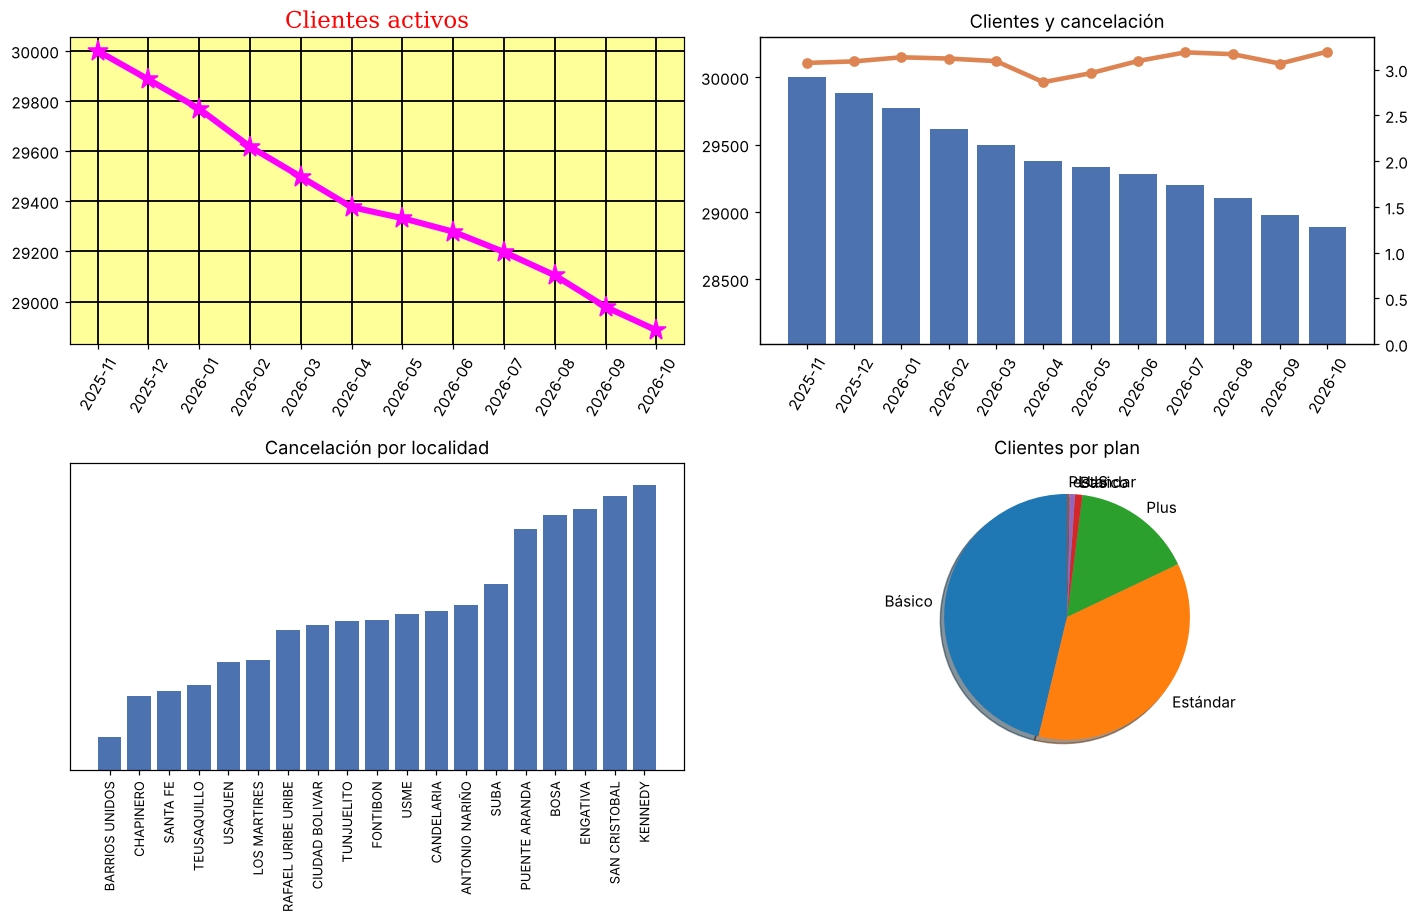

In [4]:
# Ejecute esta celda sin modificarla y observe el resultado.
activos = h.groupby("mes")["cliente_id"].nunique()
cancelacion = 100 * h.groupby("mes")["cancelo"].mean()
por_localidad = 100 * h[h["localidad"].isin(OFICIALES)].groupby("localidad")["cancelo"].mean().sort_values()
planes = h["plan"].value_counts()
with plt.style.context("default"):
    fig, ejes = plt.subplots(2, 2, figsize=(13, 8.5))
    a = ejes[0, 0]
    a.plot(activos.index, activos.values, color="#FF00FF", linewidth=4, marker="*", markersize=14)
    a.set_facecolor("#FFFF99"); a.grid(True, color="black", linewidth=1.2)
    a.set_title("Clientes activos", fontfamily="serif", fontsize=15, color="red"); a.tick_params(axis="x", rotation=60)
    a = ejes[0, 1]
    a.bar(activos.index, activos.values, color="#4C72B0"); a.tick_params(axis="x", rotation=60)
    a2 = a.twinx(); a2.plot(cancelacion.index, cancelacion.values, color="#DD8452", marker="o", linewidth=3)
    a.set_ylim(activos.min() * 0.97, activos.max() * 1.01); a2.set_ylim(0, cancelacion.max() * 1.05)
    a.set_title("Clientes y cancelación")
    a = ejes[1, 0]
    a.bar(por_localidad.index, por_localidad.values, color="#4C72B0")
    a.set_ylim(2.5, por_localidad.max() * 1.02); a.set_yticks([]); a.tick_params(axis="x", rotation=90, labelsize=8.5)
    a.set_title("Cancelación por localidad")
    a = ejes[1, 1]
    a.pie(planes, labels=planes.index, shadow=True, startangle=90); a.set_title("Clientes por plan")
    fig.tight_layout()
    plt.show()

*Celda adicional del grupo (no está en la plantilla): cifras que sustentan el diagnóstico.*

In [5]:
# Apoyo para el diagnóstico de la Tarea 2.
base = activos.min() * 0.97          # donde empieza el eje de las barras del gráfico 2 (así está en la celda anterior)
visible_oct, visible_nov = activos.iloc[-1] - base, activos.iloc[0] - base
print(f"Gráfico 2: el eje de las barras empieza en {miles(base)}; la barra de oct. 2026 mide {miles(visible_oct)} y la de nov. 2025, {miles(visible_nov)}: "
      f"parece el {decimal(100 * visible_oct / visible_nov, 0)} % de la otra, cuando los activos bajaron {decimal(100 * (1 - activos.iloc[-1] / activos.iloc[0]), 1)} %")
print(f"Gráfico 3: con el eje en 2,5 %, Kennedy parece {decimal((por_localidad['KENNEDY'] - 2.5) / (por_localidad['BARRIOS UNIDOS'] - 2.5), 1)} veces Barrios Unidos; "
      f"en realidad es {decimal(por_localidad['KENNEDY'] / por_localidad['BARRIOS UNIDOS'], 1)} veces")
mal_escritos = planes[~planes.index.isin(["Básico", "Estándar", "Plus"])]
print(f"Gráfico 4: la torta tiene {len(planes)} rebanadas para 3 planes; las {len(mal_escritos)} con nombre mal escrito suman {miles(mal_escritos.sum())} filas ({decimal(100 * mal_escritos.sum() / planes.sum(), 1)} %)")

Gráfico 2: el eje de las barras empieza en 28 019; la barra de oct. 2026 mide 867 y la de nov. 2025, 1 981: parece el 44 % de la otra, cuando los activos bajaron 3,7 %
Gráfico 3: con el eje en 2,5 %, Kennedy parece 8,4 veces Barrios Unidos; en realidad es 1,3 veces
Gráfico 4: la torta tiene 6 rebanadas para 3 planes; las 3 con nombre mal escrito suman 7 094 filas (2,0 %)


**Gráfico «Clientes activos»: ¿feo, malo o erróneo? ¿Por qué?**

*Consulten en la presentación:* diapositiva 11, «Tres formas en que una figura falla» (sección «El informe: feo, malo y erróneo»); diapositiva 12, «Gráfico 1 del informe: feo» (sección «El informe: feo, malo y erróneo»).

**Su respuesta:** **Feo.** Los datos están bien representados (30 000 clientes activos en nov. 2025 y 28 886 en oct. 2026), pero el estilo estorba: fondo amarillo, cuadrícula negra gruesa, línea magenta con estrellas, título rojo en tipografía serif y ejes sin título ni unidades. Para un comité de telecomunicaciones además falta decir qué es un cliente «activo» (cliente con servicio en el mes, Hogar y Móvil sumados) y rotular el eje, que no empieza en cero, para que nadie lea la baja de 3,7 % como un desplome.

**Gráfico «Clientes y cancelación»: ¿feo, malo o erróneo? ¿Por qué?**

*Consulten en la presentación:* diapositiva 11, «Tres formas en que una figura falla» (sección «El informe: feo, malo y erróneo»); diapositiva 13, «Gráfico 2 del informe: malo» (sección «El informe: feo, malo y erróneo»).

**Su respuesta:** **Malo, con un componente erróneo.** Combina barras y línea con dos ejes de escalas elegidas a conveniencia, de modo que el cruce visual entre la base de clientes y la cancelación es un artefacto de las escalas; tampoco hay leyenda ni títulos de ejes. Además las barras no empiezan en cero: el eje arranca en 28 019, la barra de octubre parece el 44 % de la de noviembre y en realidad los activos solo bajaron 3,7 %. En una telco la base y el churn son indicadores distintos y van en un panel por variable, cada uno con su escala desde cero.

**Gráfico «Cancelación por localidad»: ¿feo, malo o erróneo? ¿Por qué?**

*Consulten en la presentación:* diapositiva 11, «Tres formas en que una figura falla» (sección «El informe: feo, malo y erróneo»); diapositiva 16, «Gráfico 3 del informe: erróneo» (sección «El informe: feo, malo y erróneo»).

**Su respuesta:** **Erróneo.** El eje vertical empieza en 2,5 % y no muestra escala ni valores, así que la longitud de las barras no corresponde a las cifras: Kennedy (3,39 %) parece 3,8 veces Chapinero (2,73 %) y 8,4 veces Barrios Unidos, cuando son 1,2 y 1,3 veces. Además solo dibuja las localidades con el nombre escrito como el oficial y deja fuera 7 098 filas (2,0 %), que son otras grafías de las mismas 19 localidades. Y no dice cuántos clientes hay detrás de cada barra ni separa Hogar, Móvil pospago y Móvil prepago, segmentos con ingreso y cancelación distintos.

**Gráfico «Clientes por plan»: ¿qué le pasa?**

*Consulten en la presentación:* diapositiva 11, «Tres formas en que una figura falla» (sección «El informe: feo, malo y erróneo»); diapositiva 20, «Gráfico 4 del informe: la torta» (sección «El informe: feo, malo y erróneo»).

**Su respuesta:** **Discutible como gráfico y con datos sin limpiar.** Una torta es difícil de leer con rebanadas pequeñas; aquí además lleva sombra y las etiquetas de las pequeñas se superponen. Tiene 6 rebanadas para solo 3 planes (Básico, Estándar, Plus): «Basico», «estandar» y «PLUS» suman 7 094 filas (2,0 %) que no se agrupan con su plan. Y cuenta clientes-mes, no clientes, de planes que no significan lo mismo en cada segmento (velocidad en Hogar, datos incluidos en Móvil pospago, hábito de recarga en prepago): mejor barras ordenadas, por segmento y con tasas, después de limpiar los nombres (S3).

## Tarea 3 — El diccionario, los tipos de datos y las estéticas

Con el diccionario de datos a la vista, construyan una tabla `tipos` con una fila por columna (o grupo de columnas
del mismo tipo): tipo de variable según Wilke (2019, p. 9, Tabla 2-1) y la estética apropiada (Wilke, 2019,
pp. 7–8). Atención: el tipo que importa es el de **lo que la columna representa**, no el que pandas le asigna (por
ejemplo, `codigo_upz` es un número, pero es un código).

*Consulten en la presentación:* diapositiva 25, «Datos y estéticas» (sección «Datos, estéticas, escalas y coordenadas»).

In [6]:
# Tabla de tipos de variable (Wilke, 2019, Tabla 2-1) y estética apropiada, según lo que cada columna REPRESENTA.
tipos = pd.DataFrame([
    ("cliente_id", "Texto (identificador de cliente; cada cliente tiene una sola línea)", "Ninguna: no es una cantidad ni una categoría para comparar; se usa para contar clientes distintos (la base)"),
    ("mes", "Fecha (mes)", "Posición en el eje x (orden temporal)"),
    ("fecha_alta", "Fecha", "Posición en un eje de tiempo, o se resume como antigüedad; permite contar altas por mes"),
    ("codigo_upz", "Cualitativa sin orden (código)", "Color o posición en un mapa; nunca tamaño, no se suma ni se promedia"),
    ("upz, localidad", "Cualitativa sin orden (factor con muchos niveles: 102 UPZ con clientes y 19 localidades)", "Posición (barras ordenadas por la medida); en un mapa, la categoría define el polígono y el color codifica la medida"),
    ("estrato", "Cualitativa ordenada (1 a 6; aproximación a la capacidad de pago)", "Color en escala ordenada (de menos a más intenso) o posición ordenada"),
    ("latitud, longitud", "Cuantitativa continua", "Posición (x, y en un mapa, mejor con proyección); hay 5 328 filas vacías y 1 048 con los valores invertidos"),
    ("linea, modalidad", "Cualitativa sin orden", "Color o forma, o un panel por categoría"),
    ("segmento (se deriva de linea y modalidad)", "Cualitativa sin orden: Hogar pospago, Móvil pospago, Móvil prepago", "Un panel o un color por segmento: es la unidad natural para comparar cancelación e ingreso"),
    ("plan", "Cualitativa ordenada (Básico < Estándar < Plus); su significado cambia según el segmento", "Color en escala ordenada o posición; leerlo siempre dentro de su segmento"),
    ("antiguedad_meses", "Cuantitativa discreta (meses)", "Posición (eje) o color; sirve para ver si se cancela más en los primeros meses"),
    ("ingreso_mensual_cop", "Cuantitativa continua (COP por mes que paga el cliente): tarifa en pospago, recarga del mes en prepago", "Posición, o tamaño para comparar magnitudes; no se promedian juntos pospago y prepago"),
    ("uso_datos_gb", "Cuantitativa continua (muy sesgada y distinta por segmento: mediana de 259 GB en Hogar, 13 en Móvil pospago y 5,5 en prepago)", "Posición en escala logarítmica rotulada, dentro de cada segmento"),
    ("quejas_mes", "Cuantitativa discreta (conteo)", "Posición o tamaño; se compara por cada 1 000 clientes, no en cifras absolutas"),
    ("nps", "Cualitativa ordenada (0 a 10; en los datos, de 2 a 10), con 78,5 % de vacíos: es una muestra de las encuestas enviadas", "Posición o color ordenado; el curso trabaja con la respuesta y su promedio por zona (el NPS de la industria es el % de promotores, 9-10, menos el % de detractores, 0-6); los vacíos ni se eliminan, porque se perdería la base, ni se rellenan por persona, porque sería inventar la calificación"),
    ("cancelo", "Cualitativa sin orden (binaria: 0 = no, 1 = sí): cancelación registrada por el sistema, que no equivale a churn", "Color (dos categorías); su promedio es una proporción y va en posición"),
    ("tipo_cancelacion", "Cualitativa sin orden: Voluntaria, Cambio de plan (migración, no es baja), Sin recarga (solo prepago) y Por mora (solo pospago); vacía si no hubo cancelación", "Color o forma; en barras, posición ordenada por frecuencia; separa la cancelación que una campaña puede evitar de la que no"),
], columns=["Columna", "Tipo de variable", "Estética apropiada"])
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(tipos)


,Columna,Tipo de variable,Estética apropiada
0,cliente_id,Texto (identificador de cliente; cada cliente tiene una sola línea),Ninguna: no es una cantidad ni una categoría para comparar; se usa para contar clientes distintos (la base)
1,mes,Fecha (mes),Posición en el eje x (orden temporal)
2,fecha_alta,Fecha,"Posición en un eje de tiempo, o se resume como antigüedad; permite contar altas por mes"
3,codigo_upz,Cualitativa sin orden (código),"Color o posición en un mapa; nunca tamaño, no se suma ni se promedia"
4,"upz, localidad",Cualitativa sin orden (factor con muchos niveles: 102 UPZ con clientes y 19 localidades),"Posición (barras ordenadas por la medida); en un mapa, la categoría define el polígono y el color codifica la medida"
5,estrato,Cualitativa ordenada (1 a 6; aproximación a la capacidad de pago),Color en escala ordenada (de menos a más intenso) o posición ordenada
6,"latitud, longitud",Cuantitativa continua,"Posición (x, y en un mapa, mejor con proyección); hay 5 328 filas vacías y 1 048 con los valores invertidos"
7,"linea, modalidad",Cualitativa sin orden,"Color o forma, o un panel por categoría"
8,segmento (se deriva de linea y modalidad),"Cualitativa sin orden: Hogar pospago, Móvil pospago, Móvil prepago",Un panel o un color por segmento: es la unidad natural para comparar cancelación e ingreso
9,plan,Cualitativa ordenada (Básico < Estándar < Plus); su significado cambia según el segmento,Color en escala ordenada o posición; leerlo siempre dentro de su segmento


## Tarea 4 — Rehacer los gráficos defectuosos

La celda de la Tarea 2 ya calculó `por_localidad` (cancelación registrada por localidad, en %), `activos` (clientes
activos por mes) y `cancelacion` (cancelación registrada por mes, en %): úsenlos, no hace falta recalcularlos.

1. Rehagan el gráfico erróneo: barras desde cero, ordenadas, con los valores y un título que diga la conclusión.
   El título compara **Kennedy con Chapinero**: cuántas veces es la una la otra con el eje desde cero y cuántas
   parecía con el eje en 2,5 %.
2. Rehagan el gráfico malo: un panel por variable, cada uno con su escala desde cero.

*Consulten en la presentación:* diapositiva 18, «Corrección del gráfico erróneo» (sección «El informe: feo, malo y erróneo»); diapositiva 14, «Corrección del gráfico malo» (sección «El informe: feo, malo y erróneo»).

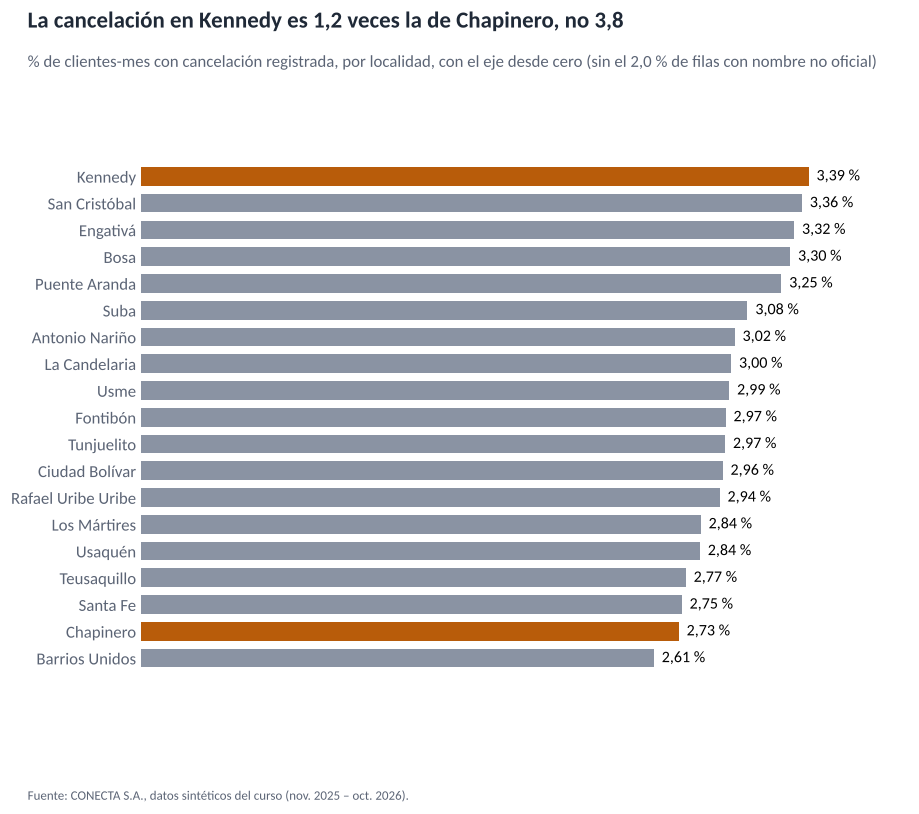

In [7]:
# Gráfico erróneo rehecho: barras desde cero, ordenadas, con los valores y un título que dice la conclusión.
NOMBRES = {"CIUDAD BOLIVAR": "Ciudad Bolívar", "ENGATIVA": "Engativá", "FONTIBON": "Fontibón", "LOS MARTIRES": "Los Mártires",
           "SAN CRISTOBAL": "San Cristóbal", "USAQUEN": "Usaquén", "CANDELARIA": "La Candelaria"}   # el archivo trae los nombres sin tilde
real = por_localidad["KENNEDY"] / por_localidad["CHAPINERO"]
aparente = (por_localidad["KENNEDY"] - 2.5) / (por_localidad["CHAPINERO"] - 2.5)
fuera_pct = 100 * (~h["localidad"].isin(OFICIALES)).mean()
orden_loc = por_localidad.sort_values()               # de menor a mayor: la barra más larga queda arriba
colores = [PALETA["acento"] if l in ("KENNEDY", "CHAPINERO") else PALETA["neutro"] for l in orden_loc.index]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh([NOMBRES.get(l, l.title()) for l in orden_loc.index], orden_loc.values, color=colores, height=0.7)
for i, v in enumerate(orden_loc.values):
    ax.text(v + 0.04, i, f"{decimal(v, 2)} %", va="center", fontsize=10.5)
limpiar_ejes(ax)
ax.set_xlim(0, orden_loc.max() * 1.15)
titulo(fig, f"La cancelación en Kennedy es {decimal(real, 1)} veces la de Chapinero, no {decimal(aparente, 1)}",
       f"% de clientes-mes con cancelación registrada, por localidad, con el eje desde cero (sin el {decimal(fuera_pct, 1)} % de filas con nombre no oficial)")
fuente(fig, FUENTE_CONECTA)
plt.show()


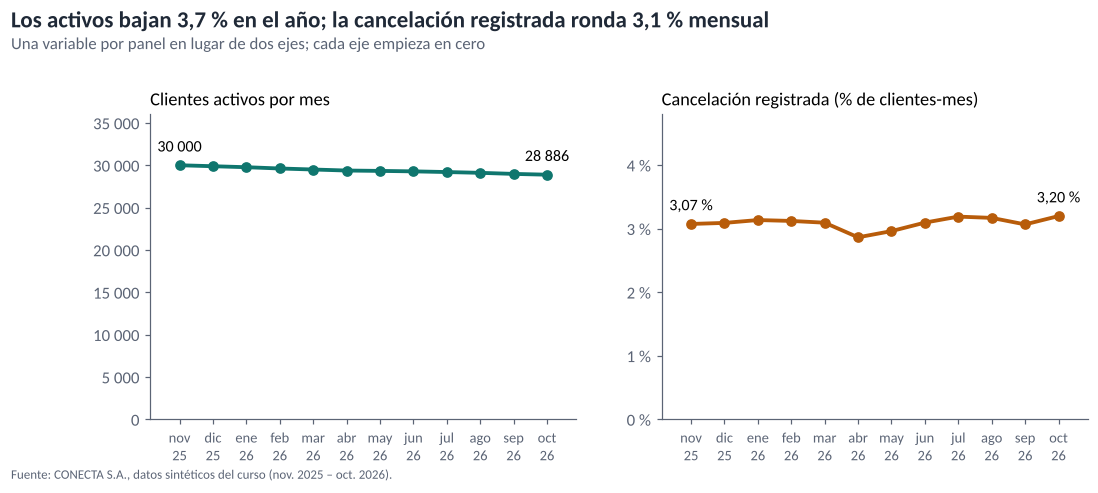

In [8]:
# Gráfico malo rehecho: un panel por variable, cada uno con su escala desde cero.
from matplotlib.ticker import FuncFormatter

meses = list(activos.index)
x = range(len(meses))
MES = "ene feb mar abr may jun jul ago sep oct nov dic".split()
etiquetas = [f"{MES[int(m[5:]) - 1]}\n{m[2:4]}" for m in meses]
baja = 100 * (1 - activos.iloc[-1] / activos.iloc[0])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(x, activos.values, color=PALETA["principal"], linewidth=2.5, marker="o")
a1.set_ylim(0, activos.max() * 1.2)
a2.plot(x, cancelacion.values, color=PALETA["acento"], linewidth=2.5, marker="o")
a2.set_ylim(0, cancelacion.max() * 1.5)
for ax, serie, nombre, fmt in ((a1, activos, "Clientes activos por mes", miles),
                               (a2, cancelacion, "Cancelación registrada (% de clientes-mes)", lambda v: decimal(v, 2) + " %")):
    ax.set_title(nombre, loc="left", fontsize=12)
    ax.margins(x=0.08)
    ax.set_xticks(list(x), etiquetas, fontsize=9.5)
    for i in (0, len(serie) - 1):
        ax.annotate(fmt(serie.iloc[i]), (i, serie.iloc[i]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=10.5)
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: miles(v)))
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: decimal(v, 0) + " %"))
titulo(fig, f"Los activos bajan {decimal(baja, 1)} % en el año; la cancelación registrada ronda {decimal(cancelacion.mean(), 1)} % mensual",
       "Una variable por panel en lugar de dos ejes; cada eje empieza en cero", y=1.1)
fuente(fig, FUENTE_CONECTA)
plt.show()


**Antes de las preguntas de interpretación.** Ejecuten la celda sin modificarla: resume cada localidad (con su nombre
oficial y los datos todavía sin revisar) con lo que el gráfico corregido no muestra: cuántos clientes tiene, cuántas
cancelaciones registró, en qué puesto queda por número y por tasa, y cuántas UPZ y estratos agrupa.

In [9]:
# Ejecute esta celda sin modificarla y observe el resultado.
loc = h[h["localidad"].isin(OFICIALES)].groupby("localidad").agg(
    clientes=("cliente_id", "nunique"), cancelaciones=("cancelo", "sum"), tasa_pct=("cancelo", "mean"),
    upz=("codigo_upz", "nunique"), estrato_min=("estrato", "min"), estrato_max=("estrato", "max"))
loc["tasa_pct"] = 100 * loc["tasa_pct"]
loc = loc.sort_values("tasa_pct", ascending=False)
loc["puesto_tasa"] = range(1, len(loc) + 1)
loc["puesto_cancelaciones"] = loc["cancelaciones"].rank(ascending=False, method="min").astype(int)
display(loc.round(2))

,clientes,cancelaciones,tasa_pct,upz,estrato_min,estrato_max,puesto_tasa,puesto_cancelaciones
localidad,,,,,,,,
KENNEDY,4901,1551,3.39,11,1,4,1,2
SAN CRISTOBAL,1626,503,3.36,5,1,3,2,9
ENGATIVA,3915,1225,3.32,8,1,5,3,3
BOSA,2271,701,3.30,5,1,3,4,5
PUENTE ARANDA,1220,368,3.25,5,2,4,5,10
SUBA,5692,1672,3.08,10,1,6,6,1
ANTONIO NARIÑO,393,115,3.02,2,2,4,7,17
CANDELARIA,90,26,3.00,1,1,3,8,19
USME,1176,333,2.99,6,1,2,9,12


## Tarea 5 — Qué debió concluir el comité

La torta de planes ya mostró una pista. Ejecuten la celda sin modificarla: compara los nombres de localidad y de plan
que trae el archivo con los oficiales, y cuenta cuántas filas dejó fuera el informe al quedarse solo con los nombres
oficiales.

In [10]:
# Ejecute esta celda sin modificarla y observe el resultado.
print(f"Localidades oficiales: {len(OFICIALES)}; nombres distintos de localidad en el archivo: {h['localidad'].nunique()}")
fuera = ~h["localidad"].isin(OFICIALES)
print(f"Filas que el informe dejó fuera por no tener el nombre oficial: {miles(fuera.sum())} de {miles(len(h))}")
print("Ejemplos:", sorted(h.loc[fuera, "localidad"].unique())[:8])
print("Nombres de plan en el archivo:", sorted(h["plan"].unique()))

Localidades oficiales: 19; nombres distintos de localidad en el archivo: 38
Filas que el informe dejó fuera por no tener el nombre oficial: 7 098 de 354 693
Ejemplos: ['Antonio Nariño', 'Barrios Unidos', 'Candelaria', 'Chapinero', 'Ciudad Bolívar', 'Engativá', 'Fontibón', 'Kennedy']
Nombres de plan en el archivo: ['Basico', 'Básico', 'Estándar', 'PLUS', 'Plus', 'estandar']


*Celda adicional del grupo (no está en la plantilla): cifras que sustentan la respuesta.*

In [11]:
# Apoyo para la respuesta de la Tarea 5 (la limpieza completa es de la S3).
print(f"Filas: {miles(len(h))}; clientes distintos: {miles(h['cliente_id'].nunique())}")
print(f"Filas duplicadas exactas: {miles(h.duplicated().sum())} (repiten cliente y mes: {miles(h.duplicated(['cliente_id', 'mes']).sum())})")
print(f"Filas sin latitud/longitud: {miles(h['latitud'].isna().sum())}; con la longitud positiva (coordenadas invertidas): {miles((h['longitud'] > 0).sum())}")
print(f"Filas con el plan escrito distinto del oficial: {miles((~h['plan'].isin(['Básico', 'Estándar', 'Plus'])).sum())}")
resp = h["nps"].notna()
print(f"Filas con respuesta de recomendación (nps): {miles(resp.sum())} ({decimal(100 * resp.mean(), 1)} %)")
canc = h[h["cancelo"] == 1]
print(f"Cancelaciones registradas: {miles(len(canc))}, de {miles(canc['cliente_id'].nunique())} clientes distintos")
print(f"Clientes con más de una cancelación registrada: {miles((canc.groupby('cliente_id').size() > 1).sum())}")
display((100 * canc["tipo_cancelacion"].value_counts(normalize=True)).round(1).rename("% de las cancelaciones").to_frame())
primera = canc.groupby("cliente_id")["mes"].min().rename("mes_canc")
d = h.join(primera, on="cliente_id").dropna(subset=["mes_canc"])
despues = d[d["mes"] > d["mes_canc"]]
print(f"Filas de clientes en meses posteriores a su primera cancelación registrada: {miles(len(despues))}, de {miles(despues['cliente_id'].nunique())} clientes")
print(f"Clientes activos en nov. 2025: {miles(activos.iloc[0])} frente a {miles((h['mes'] == '2025-11').sum())} filas ese mes")

Filas: 354 693; clientes distintos: 36 601
Filas duplicadas exactas: 1 765 (repiten cliente y mes: 1 765)
Filas sin latitud/longitud: 5 328; con la longitud positiva (coordenadas invertidas): 1 048
Filas con el plan escrito distinto del oficial: 7 094
Filas con respuesta de recomendación (nps): 76 382 (21,5 %)
Cancelaciones registradas: 10 952, de 10 600 clientes distintos
Clientes con más de una cancelación registrada: 344


,% de las cancelaciones
tipo_cancelacion,
Voluntaria,55.0
Cambio de plan,22.7
Sin recarga,13.9
Por mora,8.3


Filas de clientes en meses posteriores a su primera cancelación registrada: 12 464, de 2 201 clientes
Clientes activos en nov. 2025: 30 000 frente a 30 159 filas ese mes


*Celda adicional del grupo (no está en la plantilla): la cancelación leída como churn de una telco y la respuesta de recomendación (nps).*

In [12]:
# La cancelación registrada leída como churn de una telco, y la respuesta de recomendación (nps).
seg = pd.Series(np.where(h["linea"] == "Hogar", "Hogar pospago", np.where(h["modalidad"] == "Pospago", "Móvil pospago", "Móvil prepago")), index=h.index)
canc = h[h["cancelo"] == 1]
base_seg = h.groupby(seg).size()
canc_seg = canc.groupby(seg[canc.index]).size()
cambio = canc[canc["tipo_cancelacion"] == "Cambio de plan"].groupby(seg[canc[canc["tipo_cancelacion"] == "Cambio de plan"].index]).size().reindex(base_seg.index, fill_value=0)
t = pd.DataFrame({
    "ingreso medio (miles COP/mes)": (h.groupby(seg)["ingreso_mensual_cop"].mean() / 1000).round(0).astype(int),
    "cancelación registrada (%)": 100 * canc_seg / base_seg,
    "cambio de plan (% de las cancelaciones)": 100 * cambio / canc_seg,
    "cancelación sin cambio de plan (%)": 100 * (canc_seg - cambio) / base_seg})
with pd.option_context("display.width", 200):
    display(t.round(2))
sin_cambio = (canc["tipo_cancelacion"] != "Cambio de plan").sum()
print(f"Conjunto: cancelación registrada {decimal(100 * h['cancelo'].mean(), 2)} % mensual; sin cambio de plan, {decimal(100 * sin_cambio / len(h), 2)} %")
evitable = canc["tipo_cancelacion"].isin(["Voluntaria", "Sin recarga"]).mean()
print(f"Voluntaria + sin recarga (lo que una campaña puede evitar): {decimal(100 * evitable, 1)} % de las cancelaciones registradas")
primera_c = canc.sort_values("mes").groupby("cliente_id").first()
vuelve = h.merge(primera_c[["mes"]].rename(columns={"mes": "mes_canc"}), left_on="cliente_id", right_index=True)
vuelve = vuelve.loc[vuelve["mes"] > vuelve["mes_canc"], "cliente_id"].unique()
print("Tipo de la primera cancelación de los clientes que siguen apareciendo después:", primera_c.loc[vuelve, "tipo_cancelacion"].value_counts().to_dict())
ultimo = h["mes"].max()
sale = (h.groupby("cliente_id")["mes"].max() < ultimo).sum()
print(f"Cuadre de la base: {miles(h['cliente_id'].nunique())} clientes distintos - {miles(sale)} que dejan de aparecer antes de {ultimo} = {miles(h['cliente_id'].nunique() - sale)} activos en {ultimo}")

resp = h["nps"].notna()
print("Respuesta de recomendación (nps) por segmento (% de registros):", {s: decimal(100 * v, 1) for s, v in resp.groupby(seg).mean().items()})
print(f"Valores observados del nps: de {int(h['nps'].min())} a {int(h['nps'].max())}; clientes con al menos una respuesta: {miles(h.loc[resp, 'cliente_id'].nunique())} de {miles(h['cliente_id'].nunique())}")


def nps_score(s):
    s = s.dropna()
    return 100 * ((s >= 9).mean() - (s <= 6).mean()), len(s)


print("NPS (% de promotores 9-10 menos % de detractores 0-6), solo entre quienes respondieron:")
casos = [("Conjunto", h["nps"])] + [(s, h.loc[seg == s, "nps"]) for s in sorted(seg.unique())]
casos += [("Registros con cancelación", h.loc[h["cancelo"] == 1, "nps"]), ("Registros sin cancelación", h.loc[h["cancelo"] == 0, "nps"])]
for nombre, serie in casos:
    v, n = nps_score(serie)
    print(f"  {nombre}: {decimal(v, 1)} ({miles(n)} respuestas)")


,ingreso medio (miles COP/mes),cancelación registrada (%),cambio de plan (% de las cancelaciones),cancelación sin cambio de plan (%)
Hogar pospago,85,2.66,42.28,1.53
Móvil pospago,51,2.86,41.25,1.68
Móvil prepago,26,3.71,0.00,3.71


Conjunto: cancelación registrada 3,09 % mensual; sin cambio de plan, 2,39 %
Voluntaria + sin recarga (lo que una campaña puede evitar): 69,0 % de las cancelaciones registradas
Tipo de la primera cancelación de los clientes que siguen apareciendo después: {'Cambio de plan': 2201}
Cuadre de la base: 36 601 clientes distintos - 7 715 que dejan de aparecer antes de 2026-10 = 28 886 activos en 2026-10
Respuesta de recomendación (nps) por segmento (% de registros): {'Hogar pospago': '21,3', 'Móvil pospago': '21,9', 'Móvil prepago': '21,7'}
Valores observados del nps: de 2 a 10; clientes con al menos una respuesta: 30 576 de 36 601
NPS (% de promotores 9-10 menos % de detractores 0-6), solo entre quienes respondieron:
  Conjunto: 30,0 (76 382 respuestas)
  Hogar pospago: 26,6 (36 698 respuestas)
  Móvil pospago: 29,5 (10 256 respuestas)
  Móvil prepago: 34,4 (29 428 respuestas)
  Registros con cancelación: 11,1 (2 308 respuestas)
  Registros sin cancelación: 30,6 (74 074 respuestas)


**¿Qué podía concluir el comité con este informe y qué hay que revisar antes de confiar en estos datos?**

*Consulten en la presentación:* diapositiva 8, «Lo que el informe nos hacía concluir» (sección «El caso y la necesidad»).

**Su respuesta:** Con este informe el comité podía creer que los clientes se desploman, que la cancelación sigue a la base y que Kennedy cancela 3,8 veces lo que Chapinero; con los datos tal como están, los activos bajan 3,7 % (30 000 a 28 886, neto de altas), la cancelación registrada ronda 3,1 % mensual y las localidades van de 2,61 % a 3,39 %, así que el informe no dice dónde concentrar la campaña ni cuánto invertir. Además, «cancelación registrada» no es churn: el 22,7 % es «cambio de plan» (una migración, no una baja; es el 42 % de las cancelaciones de pospago y ninguna de prepago) y los 2 201 clientes que siguen apareciendo después de su primera cancelación son todos de ese tipo; sin ellos el churn mensual baja a cerca de 2,4 % y la base cuadra (36 601 clientes distintos menos 7 715 que dejan de aparecer antes de oct. 2026 dan los 28 886 activos). Antes de confiar hay que revisar 7 098 filas con la localidad escrita distinto, 7 094 con el plan mal escrito, 1 765 duplicadas, 5 328 sin coordenadas y 1 048 con latitud y longitud invertidas. Y solo el 21,5 % de los registros trae respuesta de recomendación (nps): es una muestra de encuestas, así que esas filas no se descartan ni se rellenan persona por persona (sería inventar la calificación del 78,5 %); la respuesta se usa por zona, donde su promedio sí informa.

## Preguntas de interpretación

Estas preguntas preparan la S2: sus respuestas son el punto de partida del próximo taller.

*Celda adicional del grupo (no está en la plantilla): cifras y gráficos que sustentan las respuestas 1 a 3.*

Tasa por localidad: de 2,61 % (Barrios Unidos) a 3,39 % (Kennedy): 0,79 puntos porcentuales de diferencia


,filas,tasa,clientes,margen95
localidad,,,,
CANDELARIA,867,3.00,90,1.14
KENNEDY,45712,3.39,4901,0.17
CHAPINERO,12370,2.73,1270,0.29


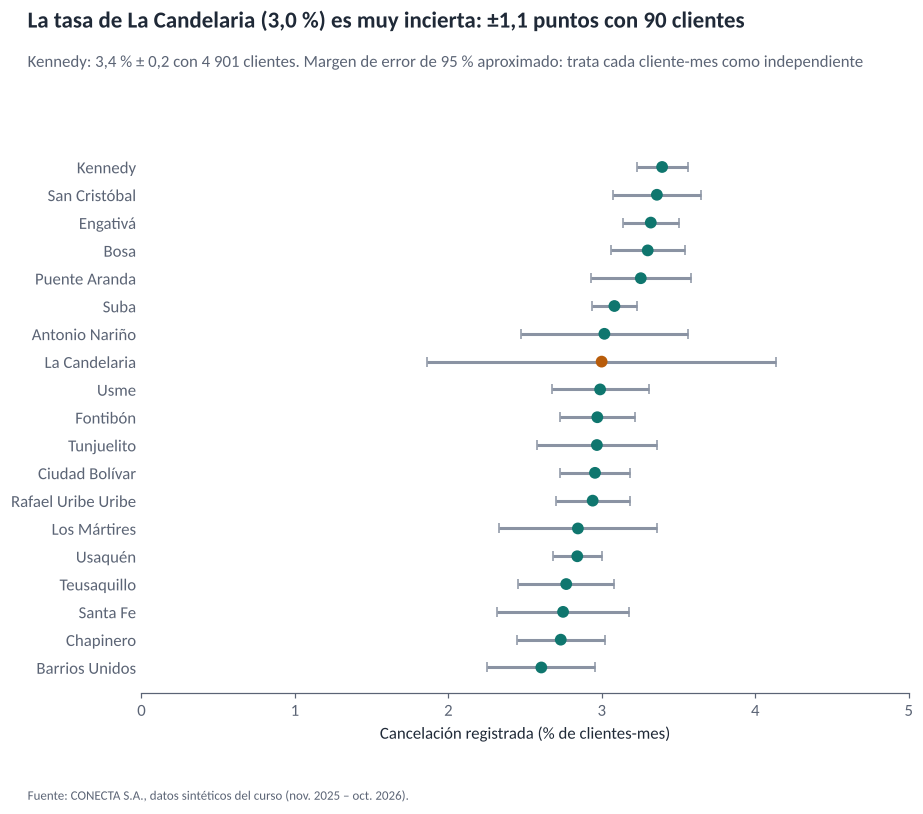

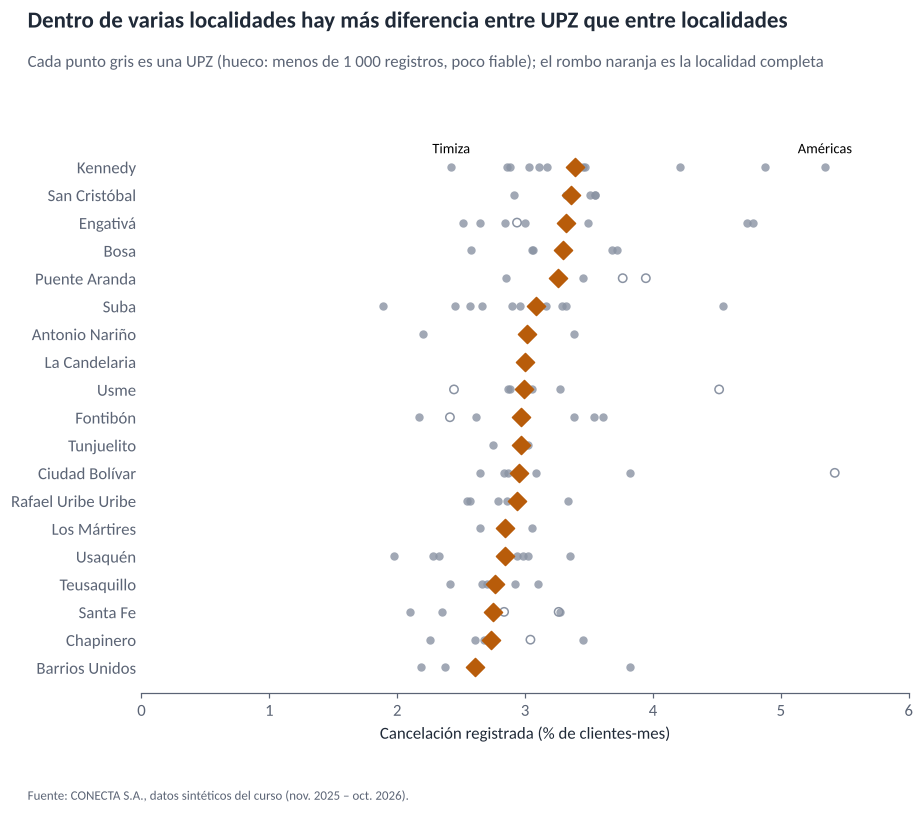

Cancelación registrada por segmento (%): {'Hogar pospago': '2,65', 'Móvil pospago': '2,86', 'Móvil prepago': '3,70'}
Participación de prepago por localidad: de 14,1 % (Teusaquillo) a 68,8 % (San Cristobal); correlación con la tasa de cancelación: 0,56
UPZ con datos y nombre de localidad oficial: 102; tasa de 1,89 % a 5,42 %; UPZ con menos de 1 000 filas: 11
Dentro de Kennedy (11 UPZ): de 2,42 % (Timiza) a 5,34 % (Américas), 2,2 veces


In [13]:
# Apoyo para las preguntas 1 a 3: usa solo las filas con nombre oficial, igual que el gráfico corregido.
of = h[h["localidad"].isin(OFICIALES)]
res = of.groupby("localidad")["cancelo"].agg(filas="size", tasa="mean")
res["tasa"] = 100 * res["tasa"]
res["clientes"] = of.groupby("localidad")["cliente_id"].nunique()
res["margen95"] = 196 * np.sqrt(res["tasa"] / 100 * (1 - res["tasa"] / 100) / res["filas"])   # 1,96 errores estándar, en puntos porcentuales
res = res.sort_values("tasa")
print(f"Tasa por localidad: de {decimal(res['tasa'].min(), 2)} % ({res['tasa'].idxmin().title()}) a {decimal(res['tasa'].max(), 2)} % ({res['tasa'].idxmax().title()}): "
      f"{decimal(res['tasa'].max() - res['tasa'].min(), 2)} puntos porcentuales de diferencia")
UPZ_NOM = {"AMERICAS": "Américas"}   # nombres de UPZ sin tilde en el archivo
display(res.loc[["CANDELARIA", "KENNEDY", "CHAPINERO"]].round(2))

seg = of.groupby(["linea", "modalidad"])["cancelo"].mean() * 100
print("Cancelación registrada por segmento (%):", {f"{a} {b.lower()}": decimal(v, 2) for (a, b), v in seg.items()})
prepago = of.groupby("localidad")["modalidad"].apply(lambda m: 100 * (m == "Prepago").mean())
print(f"Participación de prepago por localidad: de {decimal(prepago.min(), 1)} % ({prepago.idxmin().title()}) a {decimal(prepago.max(), 1)} % ({prepago.idxmax().title()}); "
      f"correlación con la tasa de cancelación: {decimal(np.corrcoef(prepago.loc[res.index], res['tasa'])[0, 1], 2)}")
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(res))
ax.errorbar(res["tasa"], y, xerr=res["margen95"], fmt="none", ecolor=PALETA["neutro"], elinewidth=2, capsize=3)
ax.scatter(res["tasa"], y, s=45, zorder=3, color=[PALETA["acento"] if l == "CANDELARIA" else PALETA["principal"] for l in res.index])
ax.set_yticks(y, [NOMBRES.get(l, l.title()) for l in res.index]); ax.set_xlim(0, 5); ax.set_xlabel("Cancelación registrada (% de clientes-mes)")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
c, k = res.loc["CANDELARIA"], res.loc["KENNEDY"]
titulo(fig, f"La tasa de La Candelaria ({decimal(c['tasa'], 1)} %) es muy incierta: ±{decimal(c['margen95'], 1)} puntos con {miles(c['clientes'])} clientes",
       f"Kennedy: {decimal(k['tasa'], 1)} % ± {decimal(k['margen95'], 1)} con {miles(k['clientes'])} clientes. Margen de error de 95 % aproximado: trata cada cliente-mes como independiente")
fuente(fig, FUENTE_CONECTA)
plt.show()

upz_t = of.groupby(["localidad", "upz"])["cancelo"].agg(filas="size", tasa="mean").reset_index()
upz_t["tasa"] = 100 * upz_t["tasa"]
print(f"UPZ con datos y nombre de localidad oficial: {len(upz_t)}; tasa de {decimal(upz_t['tasa'].min(), 2)} % a {decimal(upz_t['tasa'].max(), 2)} %; "
      f"UPZ con menos de 1 000 filas: {(upz_t['filas'] < 1000).sum()}")
kn = upz_t[upz_t["localidad"] == "KENNEDY"].sort_values("tasa")
print(f"Dentro de Kennedy ({len(kn)} UPZ): de {decimal(kn['tasa'].iloc[0], 2)} % ({UPZ_NOM.get(kn['upz'].iloc[0], kn['upz'].iloc[0].title())}) a {decimal(kn['tasa'].iloc[-1], 2)} % ({UPZ_NOM.get(kn['upz'].iloc[-1], kn['upz'].iloc[-1].title())}), "
      f"{decimal(kn['tasa'].iloc[-1] / kn['tasa'].iloc[0], 1)} veces")
fig, ax = plt.subplots(figsize=(9, 6.5))
for i, l in enumerate(res.index):
    t = upz_t[upz_t["localidad"] == l]
    grande = (t["filas"] >= 1000).values
    ax.scatter(t.loc[grande, "tasa"], np.full(grande.sum(), i), s=30, color=PALETA["neutro"], alpha=0.8, linewidths=0)
    ax.scatter(t.loc[~grande, "tasa"], np.full((~grande).sum(), i), s=30, facecolors="none", edgecolors=PALETA["neutro"], linewidths=1)
    ax.scatter(res.loc[l, "tasa"], i, s=70, marker="D", color=PALETA["acento"], zorder=3)
i_k = list(res.index).index("KENNEDY")
for u in ("TIMIZA", "AMERICAS"):
    f = kn[kn["upz"] == u].iloc[0]
    ax.annotate(UPZ_NOM.get(u, u.title()), (f["tasa"], i_k), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9.5)
ax.set_yticks(range(len(res)), [NOMBRES.get(l, l.title()) for l in res.index]); ax.set_xlim(0, 6); ax.set_xlabel("Cancelación registrada (% de clientes-mes)")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
titulo(fig, "Dentro de varias localidades hay más diferencia entre UPZ que entre localidades",
       "Cada punto gris es una UPZ (hueco: menos de 1 000 registros, poco fiable); el rombo naranja es la localidad completa")
fuente(fig, FUENTE_CONECTA)
plt.show()

*Celda adicional del grupo (no está en la plantilla): la respuesta de recomendación (nps) por zona y su relación con la cancelación.*

La tasa de cancelación usa los 347 595 registros con localidad oficial; la respuesta promedio (8,11) usa los 74 875 que respondieron
Correlación entre la respuesta promedio y la tasa de cancelación: por localidad (19) -0,29; por UPZ con al menos 200 respuestas (94) -0,64; sin las 6 UPZ de respuesta más baja (88) -0,08
Las 6 UPZ de respuesta más baja: promedio 7,4 a 7,6 y cancelación de 4,2 % a 5,3 %; las otras 88: promedio 8,2 y cancelación media de 2,9 %
UPZ con la respuesta promedio más baja (al menos 200 respuestas):


registros  tasa  nps_prom  respuestas
localidad upz                                                   
SUBA      EL PRADO              5099  4.55      7.40        1011
ENGATIVA  LAS FERIAS            4691  4.73      7.43         982
KENNEDY   KENNEDY CENTRAL       3651  4.88      7.51         711
ENGATIVA  SANTA CECILIA         3618  4.78      7.54         727
KENNEDY   AMERICAS              2975  5.34      7.59         594
          BAVARIA               2518  4.21      7.61         476

Motivo de la cancelación (% de las cancelaciones de cada grupo):


,UPZ con respuesta más baja,resto de las UPZ
tipo_cancelacion,,
Cambio de plan,16.7,23.5
Por mora,9.2,8.2
Sin recarga,8.0,14.6
Voluntaria,66.1,53.7


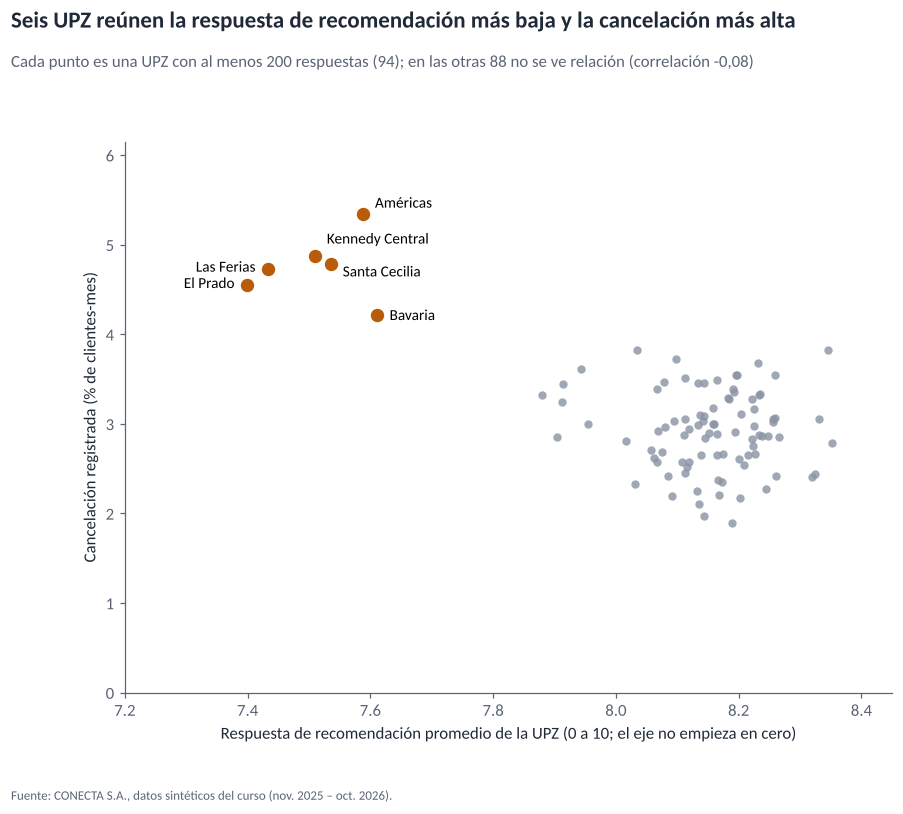

In [14]:
# La respuesta de recomendación (0 a 10) es una muestra de encuestas: no se eliminan las filas sin respuesta (se perdería la base)
# ni se rellenan por persona (sería inventar la calificación). Se promedia por zona entre quienes respondieron y se cruza con la cancelación.
of = h[h["localidad"].isin(OFICIALES)]


def por_zona(clave):
    z = of.groupby(clave).agg(registros=("cancelo", "size"), tasa=("cancelo", "mean"), nps_prom=("nps", "mean"), respuestas=("nps", "count"))
    z["tasa"] = 100 * z["tasa"]
    return z


loc_z, upz_z = por_zona("localidad"), por_zona(["localidad", "upz"])
u_ok = upz_z[upz_z["respuestas"] >= 200]
print(f"La tasa de cancelación usa los {miles(len(of))} registros con localidad oficial; la respuesta promedio ({decimal(of['nps'].mean(), 2)}) usa los {miles(of['nps'].notna().sum())} que respondieron")
bajas = u_ok.sort_values("nps_prom").head(6)
resto = u_ok.drop(bajas.index)
print(f"Correlación entre la respuesta promedio y la tasa de cancelación: por localidad ({len(loc_z)}) {decimal(loc_z['nps_prom'].corr(loc_z['tasa']), 2)}; "
      f"por UPZ con al menos 200 respuestas ({len(u_ok)}) {decimal(u_ok['nps_prom'].corr(u_ok['tasa']), 2)}; "
      f"sin las 6 UPZ de respuesta más baja ({len(resto)}) {decimal(resto['nps_prom'].corr(resto['tasa']), 2)}")
print(f"Las 6 UPZ de respuesta más baja: promedio {decimal(bajas['nps_prom'].min(), 1)} a {decimal(bajas['nps_prom'].max(), 1)} y cancelación de {decimal(bajas['tasa'].min(), 1)} % a {decimal(bajas['tasa'].max(), 1)} %; "
      f"las otras {len(resto)}: promedio {decimal(resto['nps_prom'].mean(), 1)} y cancelación media de {decimal(resto['tasa'].mean(), 1)} %")
print("UPZ con la respuesta promedio más baja (al menos 200 respuestas):")
display(bajas.round(2))
en_bajas = of.set_index(["localidad", "upz"]).index.isin(bajas.index)
cancela = (of["cancelo"] == 1).values
motivo = pd.DataFrame({"UPZ con respuesta más baja": 100 * of[en_bajas & cancela]["tipo_cancelacion"].value_counts(normalize=True),
                       "resto de las UPZ": 100 * of[~en_bajas & cancela]["tipo_cancelacion"].value_counts(normalize=True)})
print("Motivo de la cancelación (% de las cancelaciones de cada grupo):")
display(motivo.round(1))
ETIQ = {"EL PRADO": "El Prado", "LAS FERIAS": "Las Ferias", "KENNEDY CENTRAL": "Kennedy Central", "SANTA CECILIA": "Santa Cecilia",
        "AMERICAS": "Américas", "BAVARIA": "Bavaria"}
POS = {"AMERICAS": (8, 4, "left"), "KENNEDY CENTRAL": (8, 8, "left"), "SANTA CECILIA": (8, -8, "left"),
       "LAS FERIAS": (-8, -2, "right"), "EL PRADO": (-8, -2, "right"), "BAVARIA": (8, -3, "left")}   # posición de cada rótulo
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(resto["nps_prom"], resto["tasa"], s=30, color=PALETA["neutro"], alpha=0.8, linewidths=0)
for (l, u), fila in bajas.iterrows():
    dx, dy, ha = POS.get(u, (8, 4, "left"))
    ax.scatter(fila["nps_prom"], fila["tasa"], s=60, color=PALETA["acento"], zorder=3)
    ax.annotate(ETIQ.get(u, u.title()), (fila["nps_prom"], fila["tasa"]), textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=10)
ax.set_xlim(7.2, 8.45)
ax.set_ylim(0, u_ok["tasa"].max() * 1.15)
ax.set_xlabel("Respuesta de recomendación promedio de la UPZ (0 a 10; el eje no empieza en cero)")
ax.set_ylabel("Cancelación registrada (% de clientes-mes)")
titulo(fig, "Seis UPZ reúnen la respuesta de recomendación más baja y la cancelación más alta",
       f"Cada punto es una UPZ con al menos 200 respuestas ({len(u_ok)}); en las otras {len(resto)} no se ve relación (correlación {decimal(resto['nps_prom'].corr(resto['tasa']), 2)})")
fuente(fig, FUENTE_CONECTA)
plt.show()


**1. ¿Por qué comparar el número de cancelaciones entre localidades no basta para saber dónde se cancela más? Usen la tabla por localidad de la Tarea 4.**

**Su respuesta:** Porque el número depende del tamaño de la base: una localidad con muchos clientes acumula más cancelaciones aunque cancele menos en proporción. Suba es la primera por número (1 672) pero la sexta por tasa (3,08 %), y Usaquén es la cuarta por número (1 172) pero la 15.ª por tasa (2,84 %); al revés, San Cristóbal es la 9.ª por número (503) y la 2.ª por tasa (3,36 %). Para saber dónde se cancela más hay que dividir las cancelaciones entre la base del mes, como mide el churn una telco, y hacerlo por segmento, porque Hogar, Móvil pospago y Móvil prepago tienen ingreso y cancelación distintos.

**2. En el gráfico corregido, la Candelaria tiene una tasa parecida a la de localidades mucho más grandes. ¿Confiarían en su tasa tanto como en la de Kennedy? ¿Qué le falta al gráfico para saberlo?**

**Su respuesta:** No. La tasa de La Candelaria (3,00 %) sale de apenas 90 clientes (867 registros cliente-mes) y 26 cancelaciones, y su margen aproximado es de ±1,1 puntos (entre 1,9 % y 4,1 %), un rango que contiene la tasa de las otras 18 localidades; Kennedy (3,39 %) se apoya en 4 901 clientes y 1 551 cancelaciones y tiene un margen de ±0,2. Al gráfico le faltan el tamaño de la base de cada barra (clientes y cancelaciones) y un margen de incertidumbre, que es aproximado porque trata cada cliente-mes como independiente. En una campaña, una zona con tan pocos clientes no justifica un monto propio: unas pocas cancelaciones más o menos cambian su tasa.

**3. ¿Por qué la localidad puede no ser la mejor escala para decidir dónde hacer la campaña?**

**Su respuesta:** Porque la localidad promedia zonas muy distintas: las 19 localidades van de 2,61 % a 3,39 % (0,8 puntos), pero dentro de Kennedy sus 11 UPZ van de 2,42 % (Timiza) a 5,34 % (Américas), 2,2 veces, con miles de registros en cada una y márgenes que no se tocan. Una campaña dirigida a toda la localidad gastaría en zonas de baja cancelación y diluiría el esfuerzo en las de alta; la UPZ separa mejor, pero hay que mirar cuántos clientes-mes tiene cada una (11 UPZ tienen menos de 1 000), porque en las pequeñas parte de la diferencia es azar. Además, en una telco la zona es solo un criterio: en Hogar coincide con la red y la instalación, pero en Móvil la UPZ es la dirección registrada y no dice dónde usa el cliente la línea, así que la campaña también se segmenta por tipo de cliente, valor y señales de riesgo. La respuesta de recomendación señala dónde mirar: seis UPZ (El Prado, Las Ferias, Kennedy Central, Santa Cecilia, Américas y Bavaria) reúnen el promedio más bajo (7,4 a 7,6, frente a 8,2 en las demás) y la cancelación más alta (4,2 % a 5,3 %, frente a 2,9 %), mientras que en las otras 88 UPZ no hay relación (correlación -0,08).

## Interpretación final para el negocio

Para la Gerencia de Retención, en 5–8 viñetas: qué falla en el informe anterior; qué puede y qué no puede concluir el
comité; qué se debe revisar en los datos; cómo será el siguiente informe; uso de IA.

**Su respuesta:**

- **Qué falla en el informe anterior:** de los cuatro gráficos, uno es feo (clientes activos), uno malo, con un componente erróneo (doble eje con barras que no empiezan en cero), uno erróneo (cancelación por localidad con el eje en 2,5 %: Kennedy parece 3,8 veces Chapinero y es 1,2 veces) y una torta discutible con 6 rebanadas para 3 planes. Ninguno responde a la decisión del comité: no hay ingreso en juego, ni base detrás de cada tasa, ni separación por segmento.
- **Qué puede y qué no puede concluir el comité:** puede concluir que la base de clientes activos baja 3,7 % en doce meses (30 000 a 28 886), neta de altas, y que la cancelación registrada ronda 3,1 % mensual (entre 2,86 % y 3,20 %), con diferencias moderadas entre localidades (de 2,61 % a 3,39 %). No puede concluir dónde concentrar la campaña ni cuánto invertir: faltan el ingreso mensual en juego (el pago medio por cliente-mes es de unos 85 000 COP en Hogar, 51 000 en Móvil pospago y 26 000 en prepago), el tamaño de la base de cada zona (La Candelaria tiene 90 clientes, Kennedy 4 901) y qué parte de la cancelación se puede evitar; además, la localidad esconde diferencias entre UPZ (en Kennedy, de 2,42 % a 5,34 %).
- **Qué revisar en los datos (S3):** 7 098 filas con la localidad escrita distinto y 7 094 con el plan mal escrito; 1 765 filas duplicadas; 5 328 filas sin coordenadas y 1 048 con latitud y longitud invertidas; y un nps vacío en el 78,5 % de los registros. El nps es una muestra de encuestas (responde cerca de 1 de cada 5 registros, parecido en todos los segmentos): no se descartan esas filas ni se rellenan por persona, sino que se promedia por zona con su número de respuestas, y cómo imputar queda para evaluarlo en la S3.
- **Qué dice el nps por zona:** seis UPZ (El Prado, Las Ferias, Kennedy Central, Santa Cecilia, Américas y Bavaria) combinan la respuesta promedio más baja (7,4 a 7,6, frente a 8,2 en las demás) con la cancelación más alta (4,2 % a 5,3 %, frente a 2,9 %): allí hay posible insatisfacción y hay que revisar el motivo de la cancelación (la voluntaria pesa 66 % de las cancelaciones, frente a 54 % en el resto de las UPZ) y sus causas (fallas, quejas, competencia) antes de ofrecer descuentos. En las otras 88 UPZ no se ve relación (correlación -0,08), así que el nps sirve para señalar zonas, no para predecir la cancelación de cada cliente.
- **Qué significa «cancelación»:** no es churn. El «cambio de plan» (22,7 %) es una migración, no una baja, y explica los 2 201 clientes que reaparecen; «sin recarga» es la inactividad del prepago; «por mora» es una baja involuntaria que atiende cobranza, no retención. La cancelación que una campaña puede evitar es la voluntaria más la de sin recarga (69 % de lo registrado), y sin el cambio de plan el churn mensual ronda 2,4 %.
- **Qué comparar:** los segmentos no se miden con la misma regla; sin cambio de plan, Hogar pospago cancela 1,53 %, Móvil pospago 1,68 % y Móvil prepago 3,71 % (en prepago, parte de la baja es inactividad por falta de recarga). Las localidades con más prepago tienden a cancelar más (correlación 0,56 entre las 19 localidades), así que una diferencia entre zonas puede ser solo mezcla de segmentos.
- **Cómo será el siguiente informe:** abre con la petición (monto y zonas) y la ficha del comité; muestra, por UPZ y segmento, el ingreso mensual en riesgo por cancelación evitable junto a la respuesta de recomendación promedio y el motivo de la cancelación, con el número de clientes y su margen de error; usa barras desde cero con valores, títulos que dicen la conclusión y un panel por variable; y propone medir la campaña contra un grupo de control. El indicador se define en la S2.
- **Uso de IA:** se usó un asistente de IA para leer el diccionario y el notebook guiado, escribir y ejecutar el código de las Tareas 3 y 4 y de las celdas adicionales, calcular las cifras citadas y redactar borradores de las respuestas a partir del material de clase. Sirvió para decidir qué comparar (tasas e intervalos en vez de conteos), cómo clasificar cada gráfico y qué revisar en los datos.